In [90]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Sensor Scheduling using Synthetic Simulation

Trying to get bee route and synthetic sensor data. 

We are using stone soup, following these:

https://stonesoup.readthedocs.io/en/v1.9.1/auto_tutorials/sensormanagement/01_SingleSensorManagement.html#create-sensors

### Generate ground truth data


In [91]:
import numpy as np
import random
from datetime import datetime, timedelta
from stonesoup.models.transition.linear import CombinedLinearGaussianTransitionModel, ConstantVelocity
from stonesoup.types.groundtruth import GroundTruthState
from stonesoup.simulator.simple import SingleTargetGroundTruthSimulator

np.random.seed(1990)
random.seed(1990)

start_time = datetime.now().replace(microsecond=0)

# Generate transition model
# i.e. fk(xk|xk-1)
transition_model = CombinedLinearGaussianTransitionModel([ConstantVelocity(0.005),
                                                          ConstantVelocity(0.005)])

time_max = 360  # timestamps the simulation is observed over
timesteps = [start_time + timedelta(seconds=k) for k in range(time_max)]


# initial state of bee
locx = -50
locy = -50
x_velocity = 0.01
y_velocity = 0.01 
initial_state=GroundTruthState([locx, x_velocity, locy, y_velocity], timestamp=timesteps[0]),

ground_truth_simulator = SingleTargetGroundTruthSimulator(
    transition_model=transition_model,
    initial_state=GroundTruthState([locx, x_velocity, locy, y_velocity], timestamp=timesteps[0]),
    #initial_state=initial_state,
    number_steps=time_max,
    timestep=timedelta(seconds=1),
)

ground_truth = list(ground_truth_simulator)


This is an alternative to using the ground_truth_simulator, 
might be better because forces us to manually do things

- https://stonesoup.readthedocs.io/en/v1.9.1/auto_tutorials/sensormanagement/01_SingleSensorManagement.html#create-sensors
- https://stonesoup.readthedocs.io/en/v1.9.1/auto_tutorials/sensormanagement/02_MultiSensorManagement.html

In [92]:

# Generate transition model
# i.e. fk(xk|xk-1)
from stonesoup.types.groundtruth import GroundTruthPath



truth = GroundTruthPath([GroundTruthState([0, 1, 10, 1], timestamp=timesteps[0])])

for k in range(1, time_max):
    truth.append(
        GroundTruthState(transition_model.function(truth[k-1], noise=True, time_interval=timedelta(seconds=1)),
                         timestamp=timesteps[k])
    )


### Setup the sensors

In [93]:
# Load Stone Soup materials
from stonesoup.types.state import State
from stonesoup.types.array import StateVector, CovarianceMatrix

from stonesoup.platform.base import FixedPlatform 
from stonesoup.sensor.radar.radar import RadarRotatingBearing 

from stonesoup.types.state import State

from stonesoup.functions import mod_bearing

# setup the sensors

# setup the transmitter in same place as the norfolk park field experiment

transmitter_xx = [ -44.56495493,   17.54448279, -132.44165643,  127.58969322]
transmitter_yy = [-106.13383274,  207.6112732,   207.36738564,  -76.98800717]

from typing import List
sensor_platforms: List[FixedPlatform] = []

for i in range(len(transmitter_xx)):
    platform = FixedPlatform(
        State([transmitter_xx[i], transmitter_yy[i]]),  
        position_mapping=[0, 1],
        id=str(i)
    )

    # offset the starting orientation
    offset = mod_bearing(i * (np.pi/3))


    # Configure the radar noise, since we are using just a single dimension we need to specify only the
    # noise associated with the bearing dimension(, we assume a bearing accuracy of +/- 0.025 degrees for
    # each measurement
    noise_covar = CovarianceMatrix(np.array(np.diag([np.deg2rad(0.025) ** 2])))

    # instantiate the radar
    radar = RadarRotatingBearing(
        position_mapping=(0, 1),
        noise_covar=noise_covar,
        #position=[[0], [0]],
        rpm=1,
        max_range=1600,
        fov_angle=np.radians(30),
        dwell_centre=StateVector([offset]),
        #clutter_model=None,
        #resolution=np.radians(res)  # resolution of sensor equal to distance between search cells
    )

    radar.timestamp = start_time
    platform.add_sensor(radar)

    sensor_platforms.append(platform)


### Plot sensors 

Two main approaches to plotting using Stone Soup

- matplotlib based approach
- plotterly based approach

For the plotterly based approach there is the available method plot_sensor_fov which we also try to use. 
This method follows:
- https://stonesoup.readthedocs.io/en/latest/auto_examples/sensormanagement/Reinforcement_Learning_Sensor_Manager.html#run-reinforcement-learning-sensor-manager
- https://stonesoup.readthedocs.io/en/v1.9.1/auto_examples/sensormanagement/actionable_platform_example.html#plotting
    - this example is simple, like for a single sensor, maybe easiest to follow for understanding sensor_history

In [94]:
from stonesoup.plotter import AnimatedPlotterly

import copy
from collections import defaultdict

plotter = AnimatedPlotterly(timesteps, tail_length=0.1)

# "Dictionary mapping timestamps to sensor states" -- but we are just copying the sensor object? not sure about this tbh
sensor_history = defaultdict(dict)
sensor_set = [platform.sensors[0] for platform in sensor_platforms]
for ts in timesteps:
    
    # for every sensor
    for platform in sensor_platforms:
        sensor = platform.sensors[0]
        sensor.act(ts)
        sensor_history[ts][sensor] = copy.copy(sensor)


plotter.fig.data = []   # resets the graph

plotter.plot_ground_truths(ground_truth[0][1], [0,2])
plotter.plot_sensors(sensor_platforms)
plotter.plot_sensor_fov(sensor_set, sensor_history=sensor_history)
#plotter.fig.show()

### Create Detections

In [82]:
# Load the platform detection simulator - Let's use a simulator for each track
# Instantiate the simulators

# TODO not using this!

from stonesoup.simulator.platform import PlatformDetectionSimulator

radar_detection_simulator = PlatformDetectionSimulator(
    groundtruth=ground_truth_simulator,
    platforms=sensor_platforms)





### Bearing only example using EKF

Following:
- https://stonesoup.readthedocs.io/en/stable/auto_examples/filters/bearing_only_example.html#set-up-the-detection-simulation-that-generates-the-bearing-measurements
- also https://stonesoup.readthedocs.io/en/v1.1/auto_tutorials/sensormanagement/02_MultiSensorManagement.html

In [83]:
# Load the filter components
from stonesoup.types.hypothesis import SingleHypothesis

from stonesoup.types.state import GaussianState

from stonesoup.updater.kalman import ExtendedKalmanUpdater
from stonesoup.predictor.kalman import ExtendedKalmanPredictor
from stonesoup.types.track import Track


# initialise the filter to exactly where the ground truth is  

prior = (GaussianState([[locx], [x_velocity], [locy], [y_velocity]],
                                np.diag([0.5, 0.5, 0.5, 0.5]+np.random.normal(0, 5e-4, 4)),
                                timestamp=start_time))


# set the track so it begins with the prior
track = Track([prior])



predictor = ExtendedKalmanPredictor(transition_model)

updater = ExtendedKalmanUpdater(measurement_model=None)

# "Dictionary mapping timestamps to sensor states"
sensor_history = defaultdict(dict)
sensor_set = [platform.sensors[0] for platform in sensor_platforms]

sensor_measurements = []

for ts in timesteps[1:]:

    measurements = set()  # measurements at timestep 

    # check for measurements for each sensor
    for platform in sensor_platforms:
        sensor: RadarRotatingBearing = platform.sensors[0]

        sensor.act(ts)
        measurements |= sensor.measure([truth[ts]])

        sensor_history[ts][sensor] = copy.copy(sensor)

    # evovle filter 
    prediction = predictor.predict(track[-1], timestamp=ts)

    if measurements:
        for detection in measurements:
            # if there are detections update
            hypothesis = SingleHypothesis(
                prediction,
                detection
            )
            prediction = updater.update(hypothesis)
        track.append(prediction)
    else:
        # no detection prediction only
        track.append(prediction)


    # plotting the detections at timestep if any
    if measurements:
        for detection in measurements:
            
            sensor_measurements.append((ts, detection.state_vector)) 



In [95]:
plotter.fig.data = []   # resets the graph

plotter.plot_ground_truths(ground_truth[0][1], [0,2])
plotter.plot_sensors(sensor_platforms)
plotter.plot_sensor_fov(sensor_set, sensor_history=sensor_history)
plotter.plot_tracks(track, [0,2], uncertainty=True, plot_history=False, )
plotter.fig.show()

In [27]:
plotter.fig.update_layout(
    yaxis=dict(
        scaleanchor="x",
        scaleratio=1
    )
)
plotter.fig.show()

### Particle Filter

Tutorials for following particle filter includes:
- https://stonesoup.readthedocs.io/en/v0.9.1/auto_tutorials/sensormanagement/01_SingleSensorManagement.html#create-sensors



In [ ]:
from stonesoup.sensor.radar.radar import RadarRotatingBearingRange


import numpy as np
import random
from ordered_set import OrderedSet
from datetime import datetime, timedelta

start_time = datetime.now().replace(microsecond=0)

from stonesoup.models.transition.linear import CombinedLinearGaussianTransitionModel, \
    ConstantVelocity
from stonesoup.types.groundtruth import GroundTruthPath, GroundTruthState


np.random.seed(1990)
random.seed(1990)

# Generate transition model
# i.e. fk(xk|xk-1)
transition_model = CombinedLinearGaussianTransitionModel([ConstantVelocity(0.005),
                                                          ConstantVelocity(0.005)])




#yps = range(0, 100, 10)  # y value for prior state
#truths = OrderedSet() 
#ntruths = 3  # number of ground truths in simulation
time_max = 20  # timestamps the simulation is observed over
timesteps = [start_time + timedelta(seconds=k) for k in range(time_max)]

xdirection = 1
ydirection = 1

truth = GroundTruthPath([GroundTruthState([0, 1, 10, 1], timestamp=timesteps[0])])

for k in range(1, time_max):
    truth.append(
        GroundTruthState(transition_model.function(truth[k-1], noise=True, time_interval=timedelta(seconds=1)),
                         timestamp=timesteps[k])
    )


from stonesoup.plotter import AnimatedPlotterly

plotter = AnimatedPlotterly(timesteps, tail_length=1)
plotter.plot_ground_truths(truth, [0, 2])
plotter.fig


In [ ]:
# TODO 

# Sensor Scheduling using trial data

Use Norfolk park field trial data

Parsing the field trial data.


### Accessing Norfolk Park field trial data

In [5]:

#path_to_data = "March 26 2025 Field Trial/straightpath1/straightpath1.log"
#dev_kit_data = Signals(path_to_data, ['c', 'a', 'b', 'e'], filetype='.log', angleOffset=0)

# key is the name of the route, entry is a tuple of form (log file path, csv file path)
routes = {
    '8': ("bluetooth_experiments/March 26 2025 Field Trial/complexpath8/complexpath8.log",
          "bluetooth_experiments/March 26 2025 Field Trial/complexpath8/2025-03-26_12_09_13_my_iOS_device.csv"),

    '9': ("bluetooth_experiments/March 26 2025 Field Trial/complexpath9/complexpath9.log",
          "bluetooth_experiments/March 26 2025 Field Trial/complexpath9/2025-03-26_12_13_54_my_iOS_device.csv"),
        
    '1': ("bluetooth_experiments/March 26 2025 Field Trial/straightpath1/straightpath1.log",
          "bluetooth_experiments/March 26 2025 Field Trial/straightpath1/2025-03-26_11_37_00_my_iOS_device.csv")
                }

key = '9'
signal_data = routes[key][0]
GPS_File = routes[key][1]

testdata = Signals(signal_data,
                   ['c', 'a', 'b', 'e'], filetype='log',angleOffset=0)
testdata.summarise()

Standardising angles and times (shifting by 0.00 degrees)
Transmitter       Number of records
        a                 8467
        b                 3744
        c                14636
        e                 7515


Plot locations of the transmitters

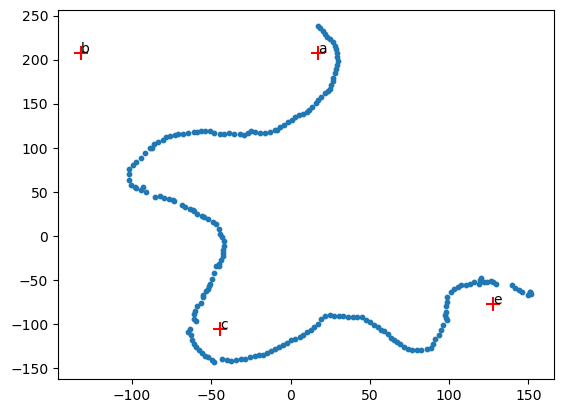

In [6]:
transmitter_labels = testdata.transmitterIDs
transmitter_latitude = [53.368359, 53.368606, 53.367865, 53.369204]
transmitter_longitude = [-1.450168, -1.448596, -1.448626, -1.449990]

GPSData = utility_methods.LoadFile(GPS_File).split('\n')
path_longitude = []
path_latitude = []
path_times = []
for coord in GPSData[1:-1]:
    coord = coord.split(',')
    path_times.append(coord[0])
    path_latitude.append(float(coord[3]))
    path_longitude.append(float(coord[4]))
    

# project into x, y coordinates and normalise
transmitter_xx, transmitter_yy, path_xx, path_yy = utility_methods.take_multiple_GPS_arrays_project_into_XY_and_normalise(transmitter_latitude, transmitter_longitude, path_latitude, path_longitude)

# plot the transmitters
plt.scatter(transmitter_xx,transmitter_yy, marker='+', s=100, c='red')
for i in range(len(transmitter_labels)):
    plt.text(transmitter_xx[i], transmitter_yy[i], transmitter_labels[i])

# plot the path
plt.scatter(path_xx, path_yy, s=10)




In [7]:
# RSSI, ID(ord of a character id), Angle(radians), Time(milliseconds since transmitter turned on)


testdata.data[0, 3]

#testdata.data.shape

np.float64(2764577.0)

###  Fitting data into StoneSoup framework then plotting as animation

Fitting ground truth into expected StoneSoup framework

In [8]:
from stonesoup.types.groundtruth import GroundTruthPath, GroundTruthState
from stonesoup.plotter import AnimationPlotter


# initial value
truth = GroundTruthPath([GroundTruthState([path_xx[0], path_yy[0]], timestamp=path_times[0])])

# for every sample append to the ground truth
for i in range(1, len(path_xx)):
    truth.append(GroundTruthState([path_xx[i], path_yy[i]], timestamp=path_times[i]))

Fitting sensors into expected StoneSoup framework format

In [28]:
from stonesoup.platform.base import FixedPlatform
from stonesoup.types.state import State

sensor_platforms = []

for i in range(len(transmitter_xx)):
    print(transmitter_xx)
    print(transmitter_yy)
    platform = FixedPlatform(
        State([transmitter_xx[i], transmitter_yy[i]]),  
        position_mapping=[0, 1],
    )
    sensor_platforms.append(platform)

[ -44.56495493   17.54448279 -132.44165643  127.58969322]
[-106.13383274  207.6112732   207.36738564  -76.98800717]
[ -44.56495493   17.54448279 -132.44165643  127.58969322]
[-106.13383274  207.6112732   207.36738564  -76.98800717]
[ -44.56495493   17.54448279 -132.44165643  127.58969322]
[-106.13383274  207.6112732   207.36738564  -76.98800717]
[ -44.56495493   17.54448279 -132.44165643  127.58969322]
[-106.13383274  207.6112732   207.36738564  -76.98800717]


Plotting as an animation

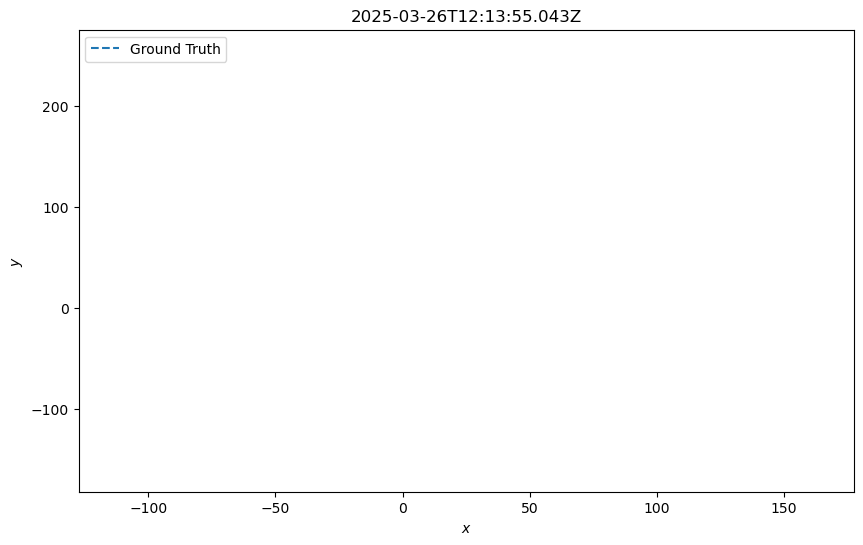

In [21]:
# plotting the track
# UGH why is it squashed? 
import matplotlib
matplotlib.rcParams['animation.html'] = 'jshtml'

plotter = AnimationPlotter(legend_kwargs=dict(loc='upper left'))
plotter.plot_ground_truths(truth, mapping=[0,1])

# plotter.scatter(transmitter_xx,transmitter_yy, marker='+', s=100, c='red')
# for i in range(len(transmitter_labels)):
#     plotter.text(transmitter_xx[i], transmitter_yy[i], transmitter_labels[i])



animation = plotter.run()

In [ ]:
# Use the figure created by the Stone Soup animation
fig = animation._fig
ax = fig.axes[0]



# from stonesoup.plotter import AnimatedPlotterly
# plotter = AnimatedPlotterly(timesteps, tail_length=0.3)
# plotter.plot_ground_truths(truth, [0, 2])
# plotter.fig

# Dummy Bayesian Adaptive Design demo using real data



### For dummy version
The bee is at an unknown location, $\theta \in [0,10]^2$.

We can make an observation, $y$ in direction $\xi$. This observation is a triplet of signal strengths at three angles around the actual angle (and transmitter) requested, $\xi$.

We need: $p(y|\theta, \xi)$:

I'll model that here with:

In [11]:
transmitter_locations = np.array([[0,0],[10,0]])

def get_dist_of_y_given_theta_xi(theta,xi):
    """
    Returns the probability distribution of observation y, given theta and xi
    
    theta = location of bee, pass as an Mx2 matrix.
    xi = tuple of id and angle of transmitter
    """
    v = theta - transmitter_locations[xi[0]]
    ang = (np.arctan2(v[:,0],v[:,1]) - xi[1]+np.pi) % (np.pi*2) #angle to bee from the transmitter specified.
    sampleangles = np.array([-0.1,0,0.1])    
    #the expected signal strengths at these sampled angles -- given the bee is actually at 'ang'
    expected_ys = -30+20*np.exp(-(ang[None,:] + sampleangles[:,None]-np.pi)**2/(2*0.1**2)).T 
    return norm(expected_ys,2)

In [12]:
#for example, we will provide two possible locations [5,5] or [6,6], if xi is from transmitter 0, pointing
#at pi/4 radians (so we sample at about 0.68, 0.78 and 0.88 signal measurements)
py = get_dist_of_y_given_theta_xi(np.array([[5,5],[6,6]]),(0,np.pi/4))
py.rvs() #we get three values (the possible measurements at the three angles, asso

array([[-21.63300078, -13.23267711, -19.19944799],
       [-16.9362777 ,  -9.67423873, -21.39910222]])

In [13]:
N = 1000
M = int(np.sqrt(N))

results = []
testangles = np.linspace(0,np.pi*2,16,endpoint=False)
for count,angle in enumerate(testangles):
    print("%d/%d" % (count,len(testangles)),end="\r")
    for transmitter_id in range(2):
        xi = (transmitter_id,angle)
        sum_p = 0
        
        for i in range(N):          
        
            # sample theta:
            theta = np.random.rand(1,2)*10 #possible locations of bees (our prior p(theta))
            # sample y|theta, xi
            py = get_dist_of_y_given_theta_xi(theta,xi)
            y_sample = py.rvs()
            
            #sample theta-prime M times...
            theta_prime = np.random.rand(M,2)*10 #possible locations of bees (our prior p(theta))
            pym = get_dist_of_y_given_theta_xi(theta_prime,xi)
            
            denom = np.mean(np.prod(pym.pdf(y_sample),1)) #compute 1/M * sum p(y_n | theta', xi)
            #divide p(y_n|theta_n,xi) by denom, to give sample
            sum_p += np.sum(py.logpdf(y_sample)) - np.log(denom) #this gives us log p(y|theta,xi) - log p(y|xi) <-- one sample of n for the EIG...
        #print(sum_p / N)
        results.append([sum_p / N, transmitter_id, angle])
results = np.array(results)

Text(0.5, 0, 'Angle / radians')

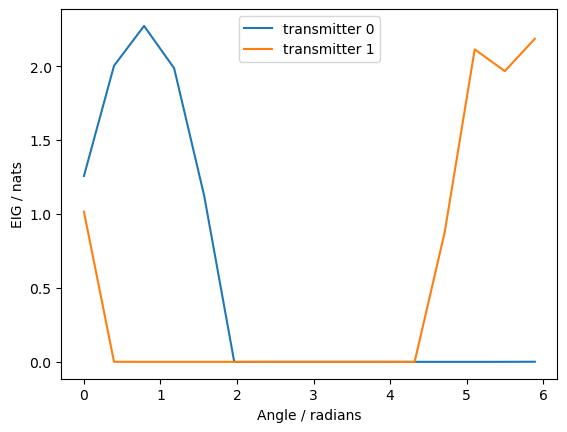

In [14]:
for i in range(2):
    plt.plot(testangles,results[i::2,0],label='transmitter %d' % i)
plt.legend()
plt.ylabel('EIG / nats')
plt.xlabel('Angle / radians')

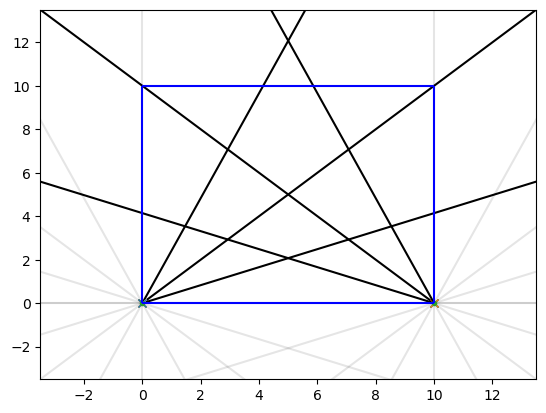

In [15]:
#here I'm just drawing all the choices that are within 0.5nats of the best EIG solution
for res in results:
    chosen = res[0]>np.max(results[:,0])-0.5
    #select = results[maxrowid]
    transmitter_loc = transmitter_locations[int(res[1])]
    ang = -res[2]-np.pi
    vector = 20*np.array([np.sin(ang),-np.cos(ang)])
    
    plt.plot(transmitter_loc[0],transmitter_loc[1],'x')
    plt.plot([transmitter_loc[0],transmitter_loc[0]+vector[0]],[transmitter_loc[1],transmitter_loc[1]+vector[1]],'-k',alpha=1 if chosen else 0.1)

plt.plot(transmitter_locations[:,0],transmitter_locations[:,1],'.')
plt.xlim([-3.5,13.5])
plt.ylim([-3.5,13.5])
plt.vlines([0,10],0,10,color='b')
plt.hlines([0,10],0,10,color='b')